### E1: Iris Data Pre-processing
This section covers:
1. **Data Cleaning**: Identifying and handling missing values in the numeric features.
2. **Data Reduction & Feature Selection**: Identifying correlated features and visualizing them with a heatmap.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/Iris.csv')

# Display basic info and first few rows
print("Dataset Summary:")
df.info()
display(df.head())

Dataset Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  139 non-null    float64
 2   SepalWidthCm   143 non-null    float64
 3   PetalLengthCm  142 non-null    float64
 4   PetalWidthCm   141 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,NaN,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [2]:
# Identify numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numeric Columns: {numeric_cols}")

# 1. Data Cleaning: Identify and fill missing values for numeric features
missing_values = df[numeric_cols].isnull().sum()
print("\nMissing values per numeric feature:")
print(missing_values)

# Fill missing values with the mean of each column (in-place)
for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mean())

print("\nMissing values handled. Current null count:")
print(df[numeric_cols].isnull().sum())

Numeric Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

Missing values per numeric feature:
Id                0
SepalLengthCm    11
SepalWidthCm      7
PetalLengthCm     8
PetalWidthCm      9
dtype: int64

Missing values handled. Current null count:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
dtype: int64


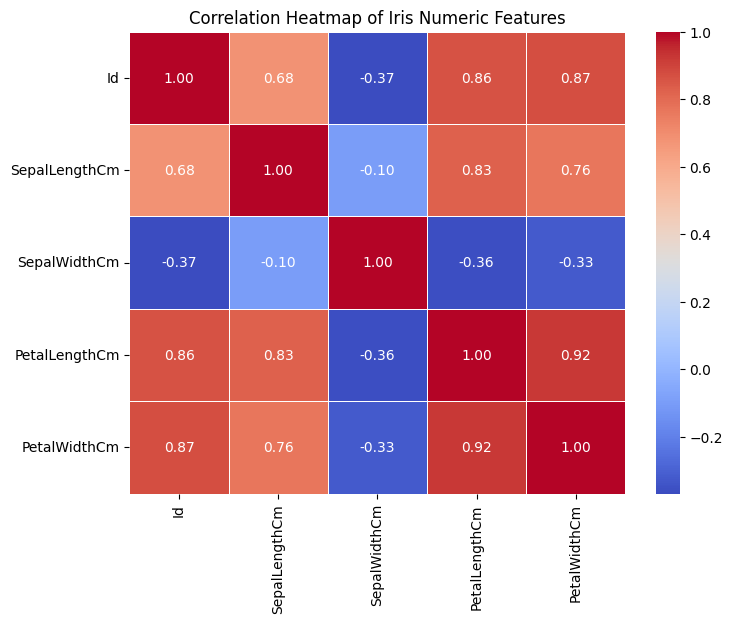


Highly correlated pairs (|r| > 0.8):


PetalWidthCm   PetalLengthCm    0.920439
               Id               0.871774
PetalLengthCm  Id               0.862372
SepalLengthCm  PetalLengthCm    0.827564
dtype: float64

In [3]:
# 2. Data Reduction: Identify correlated features and visualize correlation matrix
plt.figure(figsize=(8, 6))

# Calculate Pearson correlation coefficient for numeric features
corr_matrix = df[numeric_cols].corr()

# Plot heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Iris Numeric Features')
plt.show()

# Highlight highly correlated pairs (correlation absolute value > 0.8, excluding diagonal)
print("\nHighly correlated pairs (|r| > 0.8):")
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[high_corr < 1.0]  # Exclude self-correlation
display(high_corr[high_corr > 0.8].drop_duplicates())